# Classifying African & Asian Elephants ###

Dataset: https://www.kaggle.com/datasets/vivmankar/asian-vs-african-elephant-image-classification/data

## 1. Imports & Constants

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
TRAIN_DIR, TEST_DIR = Path("../data/train"), Path("../data/test")
RESULT_DIR = Path("../result")
MODEL_PATH = RESULT_DIR / "model" / "best_model.keras"
SEED, IMG_SIZE, BATCH_SIZE, VAL_SPLIT = 42, (224, 224), 32, 0.15

BACKBONE = (
    keras.applications.EfficientNetB0
)  # expects raw 0-255 input (built-in preprocessing)

HEAD_EPOCHS, HEAD_LR = 10, 1e-3  # stage 1: train classifier head only
FT_EPOCHS, FT_LR, FT_LAYERS = 15, 1e-5, 60  # stage 2: fine-tune top base layers
DROPOUT, PATIENCE, THRESHOLD = 0.3, 5, 0.5  # THRESHOLD is re-tuned on validation
LABEL_SMOOTHING = 0.1

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(SEED)

## 2. Data
Train folder is split into train/validation; the test folder is kept unseen for final evaluation.

In [3]:
load = lambda d, **kw: keras.utils.image_dataset_from_directory(
    d, image_size=IMG_SIZE, batch_size=None, label_mode="binary", seed=SEED, **kw
)

train_raw, val_raw = load(TRAIN_DIR, validation_split=VAL_SPLIT, subset="both")
test_raw = load(TEST_DIR, shuffle=False)
class_names = train_raw.class_names


def prep(ds, shuffle=False):
    ds = ds.cache()
    return (
        (ds.shuffle(1000, seed=SEED) if shuffle else ds)
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )


train_ds, val_ds, test_ds = prep(train_raw, True), prep(val_raw), prep(test_raw)

Found 840 files belonging to 2 classes.
Using 714 files for training.
Using 126 files for validation.
Found 188 files belonging to 2 classes.


## 3. Plot Helpers

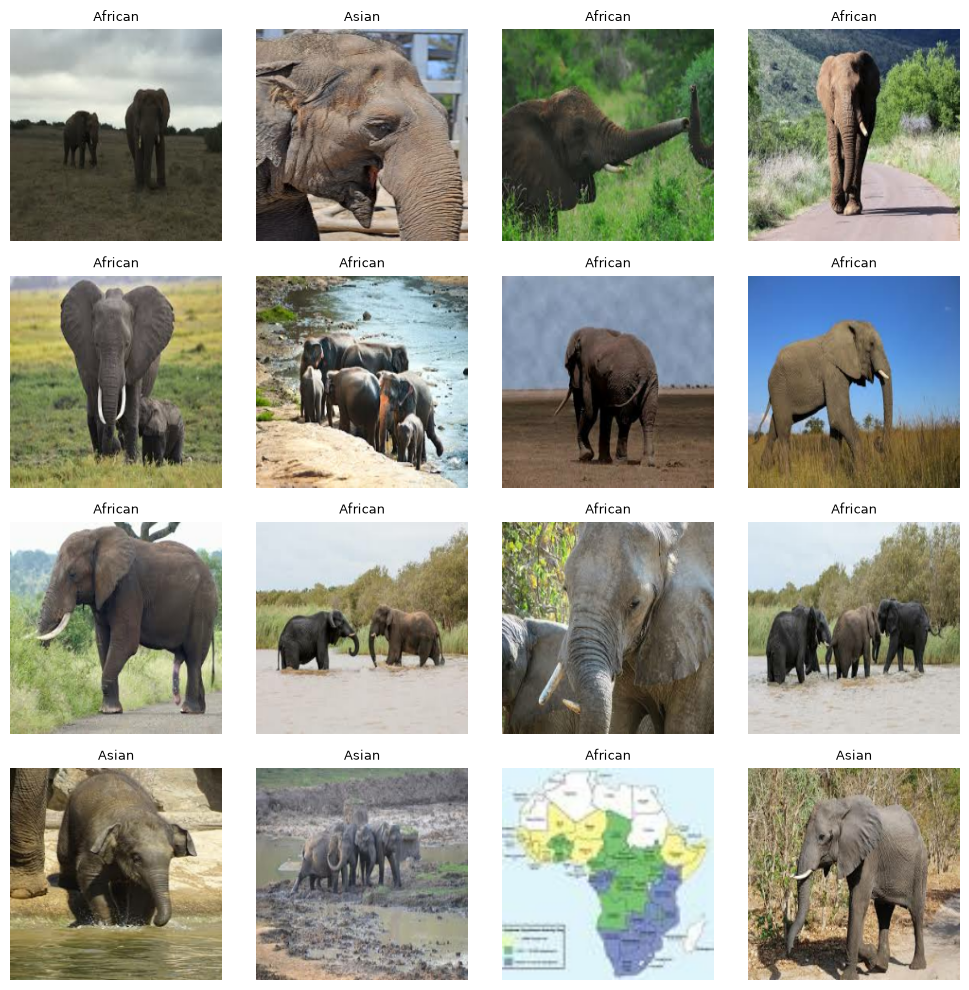

In [4]:
def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULT_DIR / name, dpi=120)
    plt.show()


def plot_grid(images, titles, name):
    plt.figure(figsize=(10, 10))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(4, 4, i + 1)
        plt.imshow(np.asarray(img).astype("uint8"))
        plt.title(title, fontsize=9)
        plt.axis("off")
    save_fig(name)


def plot_history(hists, name):
    h = {k: [v for x in hists for v in x.history[k]] for k in hists[0].history}
    _, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, m in zip(axes, ["loss", "accuracy", "auc"]):
        ax.plot(h[m], label="train")
        ax.plot(h[f"val_{m}"], label="val")
        ax.axvline(
            len(hists[0].epoch) - 0.5, ls="--", c="gray", label="fine-tune start"
        )
        ax.set(title=m, xlabel="epoch")
        ax.legend()
    save_fig(name)


imgs, labels = next(iter(train_raw.shuffle(1000, seed=SEED).batch(16)))
plot_grid(imgs, [class_names[int(l)] for l in labels.numpy().ravel()], "samples.png")

## 4. Model
Augmentation → frozen pre-trained backbone (includes its own preprocessing) → dropout → sigmoid.

In [5]:
augment = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
    ],
    name="augment",
)

base = BACKBONE(include_top=False, weights="imagenet", pooling="avg")
base.trainable = False

inputs = keras.Input(IMG_SIZE + (3,))
x = base(augment(inputs), training=False)  # keep BatchNorm in inference mode
outputs = layers.Dense(1, activation="sigmoid")(layers.Dropout(DROPOUT)(x))
model = keras.Model(inputs, outputs)
model.summary(show_trainable=True)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augment (Sequential)        │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 1280)          │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 1)             │      1,281 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 5. Training
Stage 1 trains the head; stage 2 unfreezes the top base layers (BatchNorm stays frozen). The best model by `val_loss` across both stages is saved.

In [6]:
checkpoint = keras.callbacks.ModelCheckpoint(
    MODEL_PATH, monitor="val_loss", save_best_only=True
)


def fit(lr, epochs, initial_epoch=0):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss=keras.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTHING),
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    callbacks = [
        checkpoint,
        keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.2, patience=2, min_lr=1e-7),
    ]
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=initial_epoch + epochs,
        initial_epoch=initial_epoch,
        callbacks=callbacks,
        verbose=2,
    )


hist_head = fit(HEAD_LR, HEAD_EPOCHS)

Epoch 1/10


c:\Users\Ruben\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


23/23 - 33s - 1s/step - accuracy: 0.5196 - auc: 0.5340 - loss: 0.6974 - val_accuracy: 0.6270 - val_auc: 0.6187 - val_loss: 0.6727 - learning_rate: 0.0010
Epoch 2/10
23/23 - 12s - 504ms/step - accuracy: 0.6737 - auc: 0.7152 - loss: 0.6463 - val_accuracy: 0.6746 - val_auc: 0.7393 - val_loss: 0.6385 - learning_rate: 0.0010
Epoch 3/10
23/23 - 11s - 492ms/step - accuracy: 0.7171 - auc: 0.7827 - loss: 0.6100 - val_accuracy: 0.7063 - val_auc: 0.7749 - val_loss: 0.6150 - learning_rate: 0.0010
Epoch 4/10
23/23 - 11s - 483ms/step - accuracy: 0.7199 - auc: 0.8014 - loss: 0.5909 - val_accuracy: 0.7302 - val_auc: 0.7947 - val_loss: 0.5972 - learning_rate: 0.0010
Epoch 5/10
23/23 - 11s - 476ms/step - accuracy: 0.7577 - auc: 0.8255 - loss: 0.5724 - val_accuracy: 0.7540 - val_auc: 0.8038 - val_loss: 0.5871 - learning_rate: 0.0010
Epoch 6/10
23/23 - 11s - 499ms/step - accuracy: 0.7409 - auc: 0.8256 - loss: 0.5648 - val_accuracy: 0.7381 - val_auc: 0.8096 - val_loss: 0.5814 - learning_rate: 0.0010
Epoch 

Epoch 11/25
23/23 - 37s - 2s/step - accuracy: 0.7745 - auc: 0.8651 - loss: 0.5234 - val_accuracy: 0.7698 - val_auc: 0.8238 - val_loss: 0.5600 - learning_rate: 1.0000e-05
Epoch 12/25
23/23 - 14s - 626ms/step - accuracy: 0.7829 - auc: 0.8589 - loss: 0.5257 - val_accuracy: 0.7698 - val_auc: 0.8232 - val_loss: 0.5584 - learning_rate: 1.0000e-05
Epoch 13/25
23/23 - 13s - 581ms/step - accuracy: 0.7857 - auc: 0.8696 - loss: 0.5160 - val_accuracy: 0.7619 - val_auc: 0.8274 - val_loss: 0.5552 - learning_rate: 1.0000e-05
Epoch 14/25
23/23 - 14s - 605ms/step - accuracy: 0.7787 - auc: 0.8654 - loss: 0.5159 - val_accuracy: 0.7698 - val_auc: 0.8322 - val_loss: 0.5529 - learning_rate: 1.0000e-05
Epoch 15/25
23/23 - 14s - 594ms/step - accuracy: 0.7829 - auc: 0.8662 - loss: 0.5142 - val_accuracy: 0.7698 - val_auc: 0.8346 - val_loss: 0.5517 - learning_rate: 1.0000e-05
Epoch 16/25
23/23 - 14s - 624ms/step - accuracy: 0.8081 - auc: 0.8825 - loss: 0.4977 - val_accuracy: 0.7698 - val_auc: 0.8336 - val_loss: 

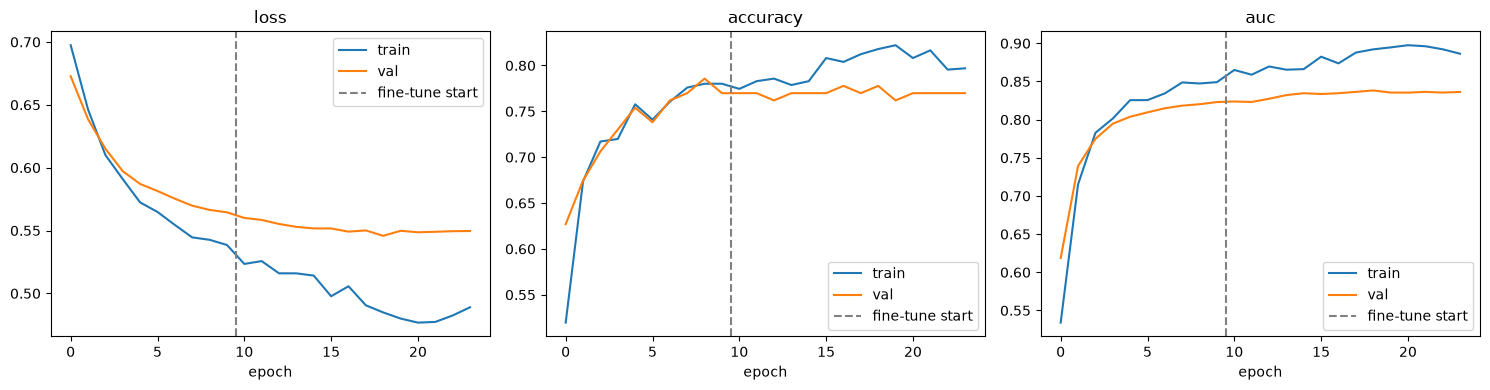

In [7]:
base.trainable = True
for i, layer in enumerate(base.layers):
    layer.trainable = i >= len(base.layers) - FT_LAYERS and not isinstance(
        layer, layers.BatchNormalization
    )

hist_ft = fit(FT_LR, FT_EPOCHS, initial_epoch=len(hist_head.epoch))
plot_history([hist_head, hist_ft], "history.png")

## 6. Evaluation

Tuned threshold: 0.40
{
  "accuracy": 0.9308510422706604,
  "auc": 0.9474340081214905,
  "loss": 0.4122391641139984,
  "tta_accuracy": 0.8936170212765957,
  "tta_auc": 0.9490200521128356
}
              precision    recall  f1-score   support

     African     0.9140    0.8763    0.8947        97
       Asian     0.8737    0.9121    0.8925        91

    accuracy                         0.8936       188
   macro avg     0.8938    0.8942    0.8936       188
weighted avg     0.8945    0.8936    0.8936       188



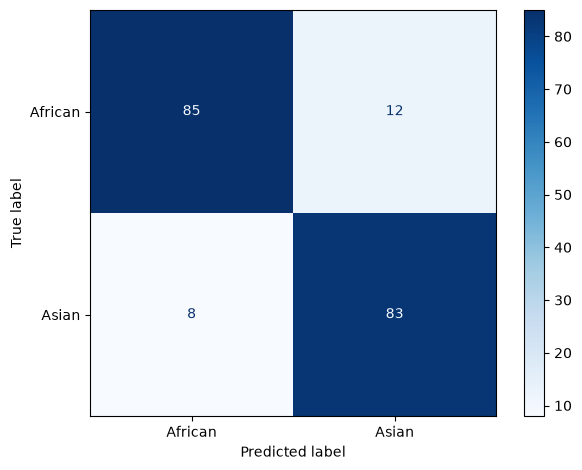

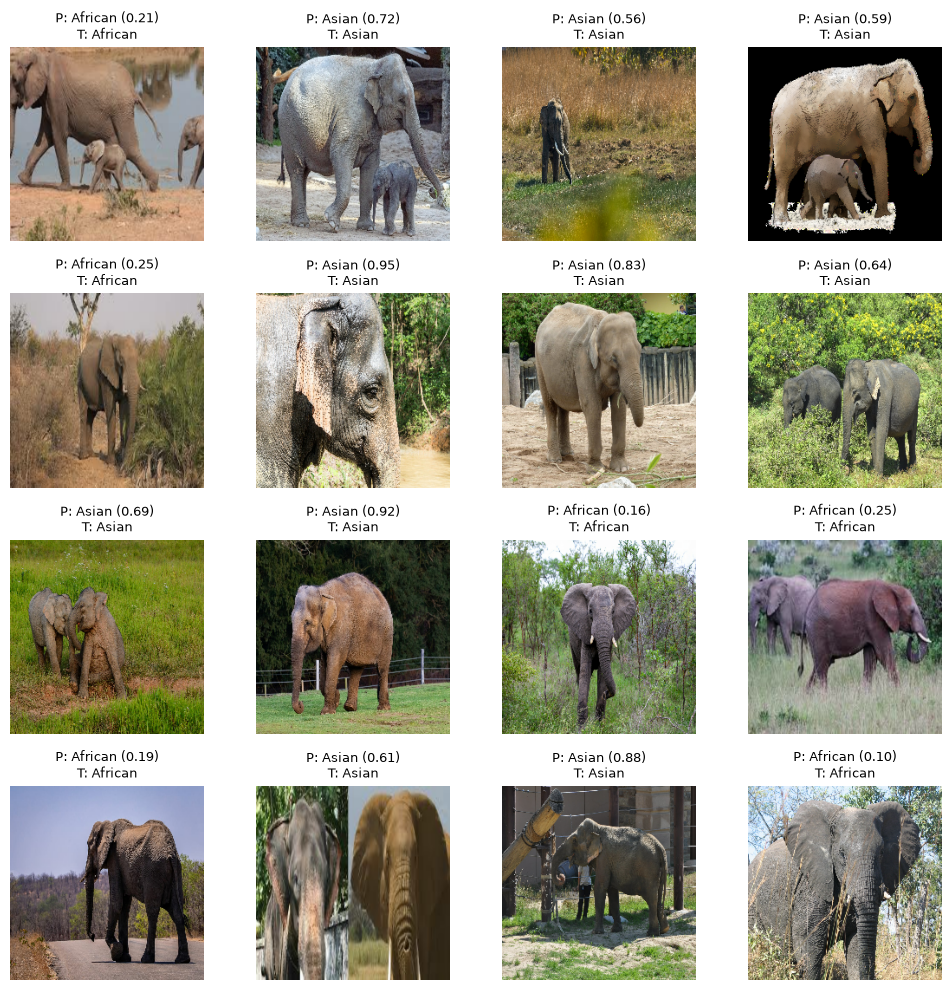

In [8]:
best = keras.models.load_model(MODEL_PATH)


def predict_tta(ds, model=best):  # average original + horizontally flipped
    x = ds.map(lambda x, y: x)
    p = model.predict(x, verbose=0).ravel()
    p_flip = model.predict(x.map(tf.image.flip_left_right), verbose=0).ravel()
    return (p + p_flip) / 2


labels_of = lambda ds: np.concatenate([y for _, y in ds]).ravel().astype(int)

# tune decision threshold on validation (never on test)
val_true, val_prob = labels_of(val_ds), predict_tta(val_ds)
cands = np.linspace(0.2, 0.8, 61)
THRESHOLD = float(
    cands[np.argmax([((val_prob >= t) == val_true).mean() for t in cands])]
)
print(f"Tuned threshold: {THRESHOLD:.2f}")

metrics = best.evaluate(test_ds, return_dict=True, verbose=0)
y_true = labels_of(test_ds)
y_prob = predict_tta(test_ds)
y_pred = (y_prob >= THRESHOLD).astype(int)
metrics["tta_accuracy"] = float((y_pred == y_true).mean())
metrics["tta_auc"] = float(roc_auc_score(y_true, y_prob))

print(json.dumps(metrics, indent=2))
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=class_names, cmap="Blues"
)

save_fig("confusion_matrix.png")

imgs, labels = next(iter(test_raw.shuffle(500, seed=SEED).batch(16)))
probs = best.predict(imgs, verbose=0).ravel()
plot_grid(
    imgs,
    [
        f"P: {class_names[int(p >= THRESHOLD)]} ({p:.2f})\nT: {class_names[int(l)]}"
        for p, l in zip(probs, labels.numpy().ravel())
    ],
    "predictions.png",
)

## 7. Inference
Load the saved best model and classify a single image file.

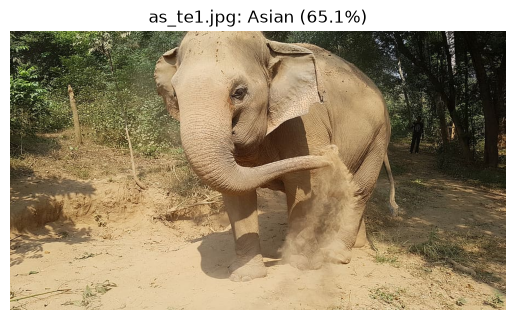

In [9]:
inference_model = keras.models.load_model(MODEL_PATH)


def predict_image(path, model=inference_model):
    img = keras.utils.load_img(
        path, target_size=IMG_SIZE
    )  # raw 0-255, preprocessing is inside the model
    prob = float(
        model.predict(keras.utils.img_to_array(img)[None], verbose=0)[0, 0]
    )  # P(class_names[1])
    idx = int(prob >= THRESHOLD)
    return class_names[idx], prob if idx else 1 - prob


sample = next((TEST_DIR / "Asian").glob("*"))
label, conf = predict_image(sample)
plt.imshow(keras.utils.load_img(sample))
plt.title(f"{sample.name}: {label} ({conf:.1%})")
plt.axis("off")
plt.show()

In [10]:
tf.keras.backend.clear_session()